### Day 2: Customer Segmentation & Feature Engineering (RFM Analysis)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score 

In [2]:
sns.set_theme(style="whitegrid")

1. Load Customer Master dataset

In [3]:
import os
print("Loading customer data for segmentation...")

customers_df='../data/clean/customer_master.csv'
if not os.path.exists(customers_df):
    customers_df = 'customer_master.csv'

df_cust = pd.read_csv(customers_df)
print(f"Total Customers Loaded: {df_cust.shape}")


Loading customer data for segmentation...
Total Customers Loaded: (10000, 7)


2. Simulate or Derive RFM Metrics for Clustering Demonstration

In [4]:
np.random.seed(42)
df_cust['Recency_Days'] = np.random.randint(1, 365, size=len(df_cust))
df_cust['Frequency'] = np.random.randint(1, 50, size=len(df_cust))

# Monetary value weighted by loyalty segment
segment_multiplier = {'Bronze': 1000, 'Silver': 3500, 'Gold': 8000, 'Platinum': 18000}
df_cust['Monetary'] = df_cust['loyalty_segment'].map(segment_multiplier) + np.random.normal(0, 500, size=len(df_cust))
df_cust['Monetary'] = df_cust['Monetary'].clip(lower=100)

print("\n--- Sample Engineered RFM Features ---")
print(df_cust[['cust_id', 'loyalty_segment', 'Recency_Days', 'Frequency', 'Monetary']].head())


--- Sample Engineered RFM Features ---
     cust_id loyalty_segment  Recency_Days  Frequency     Monetary
0  CUST00001          Silver           103         30  3817.979643
1  CUST00002          Silver           349         16  3106.881865
2  CUST00003          Bronze           271         33  1099.086135
3  CUST00004          Silver           107          2  3980.096676
4  CUST00005          Bronze            72         14   593.715716


3. Feature Scaling for K-Means Clustering

In [5]:
rfm_features = df_cust[['Recency_Days', 'Frequency', 'Monetary']]
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

4. Apply K-Means Clustering (Finding optimal 4 clusters)

In [6]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cust['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("\n--- Cluster Distribution ---")
print(df_cust['Cluster'].value_counts())


--- Cluster Distribution ---
Cluster
0    3275
1    2865
3    2840
2    1020
Name: count, dtype: int64


5. Visualizing Customer Segments (Recency vs Monetary)

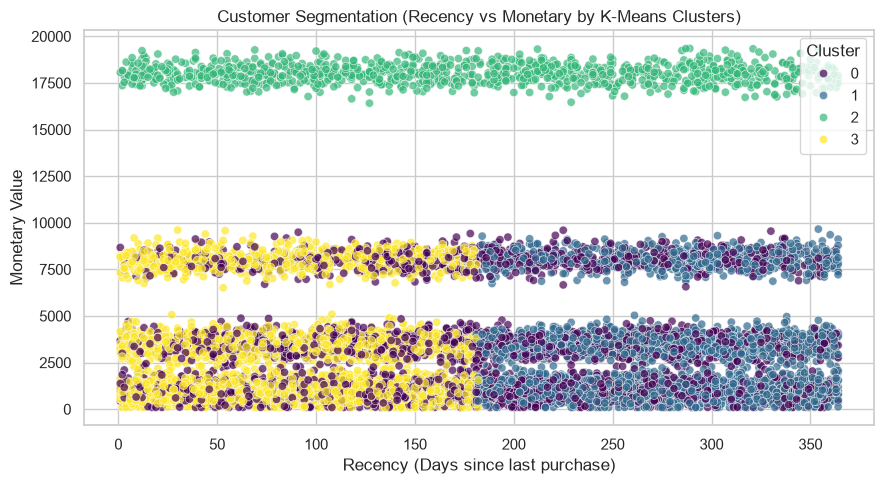


Day 2 Customer Segmentation & RFM Clustering  Completed Successfully


In [7]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_cust, x='Recency_Days', y='Monetary', hue='Cluster', palette='viridis', alpha=0.7)
plt.title('Customer Segmentation (Recency vs Monetary by K-Means Clusters)')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Monetary Value')
plt.tight_layout()
plt.savefig('../reports/customer_segments_rfm.png')
plt.show()
print("\nDay 2 Customer Segmentation & RFM Clustering  Completed Successfully")